# 02 · Evaluation

**Goal:** grade the saved matching system the way a firm would before relying on it: how often its automatic decisions are right, how much it decides with no person, where it fails and why, how it holds up on messier entries, and how it compares with the hand-written rules and with two LLMs.

| Set | Entries | What it checks |
|---|---|---|
| VAL | 601 | the same kind of entries as TRAIN, used to choose between versions |
| TEST | 597 | the same kind of entries, held back for the final check |
| Holdout file | 800 | what TRAIN never had: later dates, new phrasings, a lateral hire with no billing history |

Nothing is tuned here. The models and cutoffs come from `00_build`, and the gate lines are in `src/evaluate.py`. TEST and the holdout file were held back for the final check, but their errors were read during a review in November 2026, so a fresh file from the generator would be the cleanest check.

**Questions**
1. How often are automatic decisions right, and how much is decided with no person?
2. Does it beat the hand-written rules and CMID only?
3. Does "how sure" mean what it says, and what does each preset trade?
4. Where does it fail, and does every decision follow the checks?
5. How does it hold up on messier entries, and does it pass the gates?
6. How do two LLMs compare (from `01_llm_answers`)?

## 1. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
sys.path.insert(0, "../../extraction/src")
from classifier import route_actions
from evaluate import (GATES, TRACKED, action_metrics, add_failure_types, changed_decisions, check_decisions, check_gates,
                      compare_reports, dataset_hash, headline, matter_history, pair_metrics, parse_metrics, slice_table,
                      stress_variants)
from pipeline import decide, load_entries, load_reference, mark_true_matters, score_entries
from rules import cmid_only, run_rules, score, summarize

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
HOLDOUT_PATH = Path("../data/synthetic_time_entries_v3_HOLDOUT.xlsx")
RESULTS_DIR = Path("../results")
SETTING = "default"
SETS = ["VAL", "TEST", "HOLDOUT"]
METHODS = ["CMID only", "rules", "classifier"]
SKIP_CLIENTS = ["Firm"]   # an ordinary word, so "firm meeting" doesn't name a client
SEED = 210

LLM_DIR = Path("../data/llm_answers") / "us.amazon.nova-pro-v1_0"   # the MODEL_ID folder from 01_llm_answers
PRICE_PER_M = {"input": 0.80, "output": 3.20, "cache_read": 0.20}   # USD per million tokens, Nova Pro on Bedrock (check the Bedrock pricing page)

## 2. Load the saved system and the sets

- **Saved system:** `00_build`'s models and cutoffs (`load_reference`, the same call the app makes at startup), and the rule settings.
- **VAL and TEST** come from the main file; the **holdout file** has its own entries and the same matter list.
- **Fingerprints** are short hashes of which entries are in each set, so a changed set can't pass as the same one in a later run.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
routing = json.loads((RESULTS_DIR / "04_config.json").read_text())["routing"]
CLIENT_COL, MATTER_COL, PHRASE_MIN = feature_config["client_col"], feature_config["matter_col"], feature_config["phrase_min"]

encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
valid_cmids = set(ref["matters"]["cmid"])

main_entries, main_answers = load_entries(DATA_PATH, ref, SKIP_CLIENTS)
sets = {}
for name in [s for s in SETS if s != "HOLDOUT"]:
    rows = (main_answers["split"] == name).to_numpy()
    sets[name] = (main_entries[rows].reset_index(drop=True), main_answers[rows].reset_index(drop=True))
if "HOLDOUT" in SETS:
    holdout_matters = pd.read_excel(HOLDOUT_PATH, sheet_name="Matter Master", dtype=str)
    assert set(holdout_matters["CMID"]) == valid_cmids
    sets["HOLDOUT"] = load_entries(HOLDOUT_PATH, ref, SKIP_CLIENTS)

fingerprints = {f"{name} ids": dataset_hash(answers, ["entry_id"]) for name, (_, answers) in sets.items()}
assert all(entries["entry_id"].is_unique for entries, _ in sets.values())
print("Cutoffs:", ref["cutoffs"])
print("Fingerprints:", fingerprints)
pd.DataFrame({name: entries["source_format"].value_counts() for name, (entries, _) in sets.items()}).fillna(0).astype(int)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Cutoffs: {'auto_min': 0.9, 'no_match_min': 0.7, 'multi_min': 0.15, 'correct_typed_cmid': True, 'correct_min': 0.97}
Fingerprints: {'VAL ids': '9b266b650c26', 'TEST ids': 'd21414339749', 'HOLDOUT ids': 'cb4f24282457'}


,VAL,TEST,HOLDOUT
source_format,,,
TYPED,326,317,452
HANDWRITTEN,109,124,164
PDF,99,107,113
EMAIL,67,49,71


## 3. Run every method on every set

- **Classifier:** `decide` builds the clues, runs both models, applies the cutoffs, and writes the reasons. The time per entry includes everything.
- **Rules:** the hand-written rules on the same clues, the baseline to beat.
- **CMID only:** accept a valid typed CMID and send everything else to a person, the floor.

In [4]:
runs = {}
for name, (entries, answers) in sets.items():
    start = time.perf_counter()
    pairs, top, decisions = decide(entries, ref)
    seconds = (time.perf_counter() - start) / len(entries)
    pairs = mark_true_matters(pairs, answers)
    runs[name] = {"entries": entries, "answers": answers, "pairs": pairs, "top": top, "seconds": seconds,
                  "classifier": score(decisions, answers).merge(entries[["entry_id", "source_format"]], on="entry_id"),
                  "rules": score(run_rules(pairs, rules_config["rules"]), answers),
                  "CMID only": score(run_rules(pairs, rules_config["rules"], cmid_only), answers)}
    print(f"{name}: {len(entries)} entries | {seconds * 1000:.0f} ms per entry")

VAL: 601 entries | 4 ms per entry
TEST: 597 entries | 4 ms per entry
HOLDOUT: 800 entries | 4 ms per entry


## 4. Headline results

- `auto_share`: matched with nobody looking. `auto_precision`: of those, the share on the right matter.
- `decided_precision`: auto-matches and new-client calls together, the number the targets are set on, with `ci_low` the low end of its 95% range (resampling timekeepers).
- `silent_errors`: auto-matches on the wrong matter, the mistakes nobody sees.

In [5]:
COLS = ["auto_share", "auto_precision", "decided_precision", "ci_low", "silent_errors", "review_share", "no_match_share",
        "matter_accuracy", "multi_caught", "no_match_precision", "shortlist_hit"]
table = pd.DataFrame({(name, method): headline(run[method]) for name, run in runs.items() for method in METHODS}).T
table = table[COLS].rename_axis(["set", "method"])
table.round(3)

auto_share  auto_precision  decided_precision  ci_low  \
set     method                                                              
VAL     CMID only        0.431           0.687              0.687   0.632   
        rules            0.514           0.883              0.872   0.831   
        classifier       0.659           0.982              0.974   0.961   
TEST    CMID only        0.466           0.705              0.705   0.645   
        rules            0.563           0.857              0.846   0.808   
        classifier       0.650           0.972              0.969   0.950   
HOLDOUT CMID only        0.480           0.732              0.732   0.690   
        rules            0.570           0.890              0.881   0.846   
        classifier       0.621           0.978              0.975   0.956   

                    silent_errors  review_share  no_match_share  \
set     method                                                    
VAL     CMID only            81.0         0.569           0.000   
        rules                36.0         0.324           0.058   
        classifier            7.0         0.161           0.052   
TEST    CMID only            82.0         0.534           0.000   
        rules                48.0         0.302           0.045   
        classifier           11.0         0.166           0.052   
HOLDOUT CMID only           103.0         0.520           0.000   
        rules                50.0         0.294           0.041   
        classifier           11.0         0.191           0.040   

                    matter_accuracy  multi_caught  no_match_precision  \
set     method                                                          
VAL     CMID only             0.364         0.000                 NaN   
        rules                 0.654         0.243               0.771   
        classifier            0.875         0.838               0.871   
TEST    CMID only             0.400         0.000                 NaN   
        rules                 0.670         0.108               0.704   
        classifier            0.859         0.730               0.935   
HOLDOUT CMID only             0.410         0.000                 NaN   
        rules                 0.670         0.184               0.758   
        classifier            0.862         0.921               0.938   

                    shortlist_hit  
set     method                     
VAL     CMID only           0.693  
        rules               0.605  
        classifier          0.876  
TEST    CMID only           0.661  
        rules               0.556  
        classifier          0.818  
HOLDOUT CMID only           0.721  
        rules               0.634  
        classifier          0.837

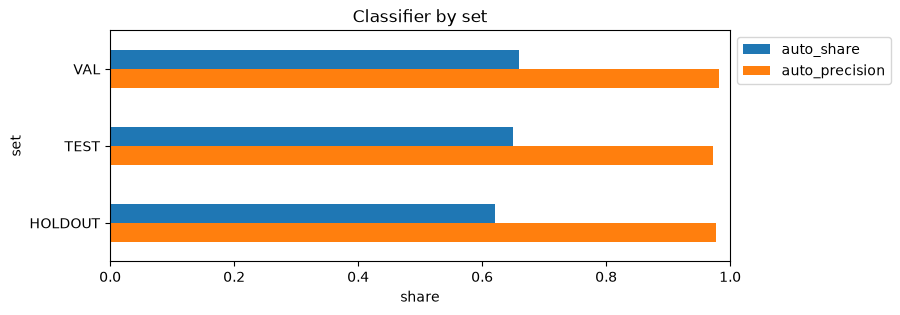

In [6]:
ax = table.xs("classifier", level="method")[["auto_share", "auto_precision"]].plot.barh(figsize=(8, 3), xlim=(0, 1), title="Classifier by set")
ax.set_xlabel("share")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

**Takeaways**


- **The classifier beats both baselines on every set.** Decided precision is 97.4%, 96.9%, and 97.5% on VAL, TEST, and the holdout file, against 87.2%, 84.6%, and 88.1% for the rules and about 70% for trusting the typed CMID.
- **It makes far fewer silent errors while deciding more:** 7, 11, and 11 against the rules' 36, 48, and 50, with 62% to 66% matched with no person against the rules' 51% to 57%.
- **About 1 entry in 6 goes to review** (16% on VAL, 17% on TEST, 19% on the holdout file, which has new phrasings and a lateral hire with no billing history).
- **Multi-matter entries:** 84%, 73%, and 92% are caught.
- Each entry takes about 4 ms.

## 5. Stage by stage

Each step can fail on its own, so measuring them apart shows where a drop comes from:
- **Emails:** whether the hours and client were read out of the email body
- **Step 1, the pair model:** top-1 and top-3 (right matter ranked first, or in the review shortlist), MRR, and the calibration error of each entry's top pick
- **Step 2, the action model:** how well P(auto), P(multi), and P(no_match) separate their entries from the rest (AUROC), and PR-AUC for multi-matter entries, which are rare enough that AUROC looks good even when the score isn't (a random score gets their share, about 6%)

In [7]:
stages = {}
for name, run in runs.items():
    emails = run["entries"][run["entries"]["source_format"] == "EMAIL"]
    stages[name] = {**{f"email {k}": v for k, v in parse_metrics(emails, run["answers"], ref["client_names"]).items()},
                    **pair_metrics(run["pairs"]),
                    **{f"step 2 AUROC, {label}": auroc for label, auroc in action_metrics(run["top"], run["answers"])["auroc"].items()},
                    "step 2 PR-AUC, multi": action_metrics(run["top"], run["answers"]).loc["multi", "pr_auc"]}
pd.DataFrame(stages).round(3)

,VAL,TEST,HOLDOUT
email emails,67.000,49.000,71.000
email hours_found,1.000,1.000,1.000
email client_filled,0.701,0.796,0.789
email right_client,0.655,0.773,0.738
email wrong_client,0.052,0.023,0.015
entries,601.000,597.000,800.000
top_1,0.933,0.909,0.886
top_3,0.991,0.971,0.959
mrr,0.960,0.941,0.924
auroc,0.996,0.994,0.991


**Takeaways**


- **Step 1 ranks the right matter first** for 93%, 91%, and 89% of entries and in the top 3 for 99%, 97%, and 96% (VAL, TEST, holdout). Most misses are a choice among a few close matters, not a missing candidate.
- **Step 2 is what makes automation safe:** its AUROC for "safe to auto-match" is 0.93 to 0.94, against 0.83 to 0.84 for step 1's top probability alone.
- **Multi-matter PR-AUC is 0.84, 0.79, and 0.90** (a random score would get about 0.06). TEST's is the lowest, and TEST is where most multi-matter misses are.
- **Emails:** the client is filled in for 70% to 80% of emails and wrong for 2% to 5%.

## 6. Does "how sure" mean what it says?

The page shows P(auto) as how sure Tenth is, and the cutoffs are set on it. For it to work as a cutoff, entries at 90% should be safe to accept about 9 times in 10. Each set's entries are binned by P(auto), and **safe** means the top pick is the right matter and the entry covers only that matter.

In [8]:
bins = [0, 0.5, 0.8, 0.9, 0.95, 0.97, 0.99, 1.0001]
pooled = []
for name, run in runs.items():
    key = run["answers"].set_index("entry_id")
    t = run["top"][["entry_id", "top_cmid", "p_auto"]].assign(set=name)
    t["safe"] = (t["top_cmid"] == t["entry_id"].map(key["key_true_cmid"])) & t["entry_id"].map(key["key_secondary_cmid"]).isna()
    pooled.append(t)
pooled = pd.concat(pooled)
pooled["band"] = pd.cut(pooled["p_auto"], bins, right=False)
pooled.groupby(["band", "set"], observed=True)["safe"].mean().unstack().join(
    pooled.groupby("band", observed=True).size().rename("entries")).round(3)

,HOLDOUT,TEST,VAL,entries
band,,,,
"[0.0, 0.5)",0.200,0.232,0.169,280
"[0.5, 0.8)",0.640,0.525,0.603,268
"[0.8, 0.9)",0.865,0.860,0.885,147
"[0.9, 0.95)",0.925,0.826,0.957,146
"[0.95, 0.97)",0.936,1.000,0.950,99
"[0.97, 0.99)",0.981,0.977,0.973,268
"[0.99, 1.0)",0.990,0.996,0.992,790


**Takeaways**


- **At the top, P(auto) means what it says:** entries at 0.99 and up are safe 99% of the time and 0.97 to 0.99 about 97% to 98%, on every set.
- **Just above the default cutoff it's less steady:** at 0.90 to 0.95, entries are safe 96%, 83%, and 93% of the time (VAL, TEST, holdout). More than half the default's silent errors on VAL and TEST (10 of 18) come from this band, which holds 84 of the 784 auto-matches.
- Calibration error is 0.046 to 0.049, just under the 0.05 line.

## 7. The presets

A firm picks one preset for how careful automatic matching is (`SETTING` when the service starts; the page can't change it). Each preset is scored here on every set with the same models, so only the cutoffs differ.

In [9]:
rows = {}
for name, run in runs.items():
    probs = run["top"][["p_auto", "p_review", "p_multi", "p_no_match"]].rename(columns=lambda c: c[2:])
    for preset in ["strict", "default", "balanced"]:
        s = summarize(score(route_actions(run["top"], probs, routing[preset]), run["answers"]))
        rows[(name, preset)] = {"auto_min": routing[preset]["auto_min"], "auto_share": s["auto_share"],
                                "auto_precision": s["auto_precision"], "silent_per_100": 100 * s["silent_errors"] / s["entries"],
                                "review_share": s["review_share"], "flag_share": s["flag_share"]}
presets = pd.DataFrame(rows).T.rename_axis(["set", "preset"])
presets.round(3)

auto_min  auto_share  auto_precision  silent_per_100  \
set     preset                                                           
VAL     strict        0.95       0.552           0.988           0.666   
        default       0.90       0.659           0.982           1.165   
        balanced      0.50       0.830           0.932           5.657   
TEST    strict        0.95       0.548           0.994           0.335   
        default       0.90       0.650           0.972           1.843   
        balanced      0.50       0.794           0.924           6.030   
HOLDOUT strict        0.95       0.536           0.984           0.875   
        default       0.90       0.621           0.978           1.375   
        balanced      0.50       0.796           0.923           6.125   

                  review_share  flag_share  
set     preset                              
VAL     strict           0.230       0.087  
        default          0.161       0.048  
        balanced         0.010       0.022  
TEST    strict           0.238       0.097  
        default          0.166       0.067  
        balanced         0.023       0.054  
HOLDOUT strict           0.251       0.090  
        default          0.191       0.065  
        balanced         0.024       0.040

**Takeaways**


- **Each preset holds close to its TRAIN numbers on all three sets:** strict matches 54% to 55% with 98.4% to 99.4% right, default 62% to 66% with 97.2% to 98.2%, and balanced 79% to 83% with 92.3% to 93.2%.
- **Silent errors per 100 entries:** 0.3 to 0.9 at strict, 1.2 to 1.8 at default, and 5.7 to 6.1 at balanced.
- **Default to strict** sends about 6 to 7 more entries per 100 to review and saves 0.5 to 1.5 silent errors per 100. Balanced cuts review to 1 to 2 per 100 but has 3 to 5 times the default's silent errors.

## 8. Slices

The classifier's numbers by source format, entry type, whether the right matter has past entries, and whether the timekeeper has billing history. Groups under 10 entries are left out.

In [10]:
slice_cols = ["entries", "auto_share", "auto_precision", "silent_errors", "review_share", "matter_accuracy"]
by_format = pd.concat({name: slice_table(run["classifier"], "source_format") for name, run in runs.items()})
by_format[slice_cols].round(3)

entries  auto_share  auto_precision  silent_errors  \
VAL     EMAIL           67.0       0.463           1.000            0.0   
        HANDWRITTEN    109.0       0.642           1.000            0.0   
        PDF             99.0       0.788           0.962            3.0   
        TYPED          326.0       0.666           0.982            4.0   
TEST    EMAIL           49.0       0.694           0.941            2.0   
        HANDWRITTEN    124.0       0.653           0.963            3.0   
        PDF            107.0       0.654           0.957            3.0   
        TYPED          317.0       0.640           0.985            3.0   
HOLDOUT EMAIL           71.0       0.507           0.944            2.0   
        HANDWRITTEN    164.0       0.646           0.972            3.0   
        PDF            113.0       0.602           0.985            1.0   
        TYPED          452.0       0.635           0.983            5.0   

                     review_share  matter_accuracy  
VAL     EMAIL               0.373            0.716  
        HANDWRITTEN         0.193            0.927  
        PDF                 0.051            0.879  
        TYPED               0.141            0.890  
TEST    EMAIL               0.163            0.796  
        HANDWRITTEN         0.169            0.919  
        PDF                 0.150            0.850  
        TYPED               0.170            0.849  
HOLDOUT EMAIL               0.296            0.704  
        HANDWRITTEN         0.189            0.878  
        PDF                 0.212            0.885  
        TYPED               0.170            0.876

In [11]:
by_type = pd.concat({name: slice_table(run["classifier"], "key_entry_category") for name, run in runs.items()})
by_type[slice_cols].round(3)

entries  auto_share  auto_precision  \
VAL     AMBIGUOUS              38.0       0.711           1.000   
        CLEAN                 148.0       0.831           1.000   
        CLOSED_OR_NOT_OPEN     10.0       0.500           1.000   
        INCOMPLETE            146.0       0.829           1.000   
        MESSY                 127.0       0.756           1.000   
        MULTI_NAMED            23.0       0.043           0.000   
        MULTI_UNNAMED          14.0       0.000             NaN   
        NO_MATCH               37.0       0.000             NaN   
        WRONG_CMID_SILENT      32.0       0.438           0.643   
        WRONG_CMID_TEXT        26.0       0.346           0.889   
TEST    AMBIGUOUS              36.0       0.389           0.857   
        CLEAN                 154.0       0.838           1.000   
        CLOSED_OR_NOT_OPEN     15.0       0.267           1.000   
        INCOMPLETE            137.0       0.832           1.000   
        MESSY                 132.0       0.795           1.000   
        MULTI_NAMED            24.0       0.250           0.000   
        MULTI_UNNAMED          13.0       0.154           0.000   
        NO_MATCH               36.0       0.000             NaN   
        WRONG_CMID_SILENT      29.0       0.207           0.833   
        WRONG_CMID_TEXT        21.0       0.381           1.000   
HOLDOUT AMBIGUOUS              48.0       0.500           0.917   
        CLEAN                 229.0       0.847           0.995   
        CLOSED_OR_NOT_OPEN     16.0       0.188           1.000   
        INCOMPLETE            192.0       0.724           0.993   
        MESSY                 168.0       0.685           0.991   
        MULTI_NAMED            19.0       0.053           0.000   
        MULTI_UNNAMED          19.0       0.000             NaN   
        NO_MATCH               37.0       0.027           0.000   
        WRONG_CMID_SILENT      40.0       0.225           0.889   
        WRONG_CMID_TEXT        32.0       0.344           0.727   

                            silent_errors  review_share  matter_accuracy  
VAL     AMBIGUOUS                     0.0         0.263            0.895  
        CLEAN                         0.0         0.149            0.993  
        CLOSED_OR_NOT_OPEN            0.0         0.000            1.000  
        INCOMPLETE                    0.0         0.130            0.952  
        MESSY                         0.0         0.173            0.921  
        MULTI_NAMED                   1.0         0.174            0.217  
        MULTI_UNNAMED                 0.0         0.000            0.714  
        NO_MATCH                      0.0         0.243            0.730  
        WRONG_CMID_SILENT             5.0         0.219            0.562  
        WRONG_CMID_TEXT               1.0         0.154            0.731  
TEST    AMBIGUOUS                     2.0         0.583            0.583  
        CLEAN                         0.0         0.123            0.961  
        CLOSED_OR_NOT_OPEN            0.0         0.000            0.933  
        INCOMPLETE                    0.0         0.124            0.956  
        MESSY                         0.0         0.182            0.939  
        MULTI_NAMED                   6.0         0.083            0.125  
        MULTI_UNNAMED                 2.0         0.000            0.846  
        NO_MATCH                      0.0         0.194            0.806  
        WRONG_CMID_SILENT             1.0         0.207            0.517  
        WRONG_CMID_TEXT               0.0         0.143            0.810  
HOLDOUT AMBIGUOUS                     2.0         0.479            0.667  
        CLEAN                         1.0         0.100            0.969  
        CLOSED_OR_NOT_OPEN            0.0         0.000            0.688  
        INCOMPLETE                    1.0         0.208            0.911  
        MESSY                         1.0         0.262            0.911  


In [12]:
for run in runs.values():
    run["classifier"]["matter_history"] = matter_history(run["classifier"], ref["past_cmids"])
    has_history = run["classifier"]["tk_id"].isin(ref["history"]["tk_id"])
    run["classifier"]["timekeeper"] = has_history.map({True: "has billing history", False: "no billing history"})
by_history = pd.concat({(name, by): slice_table(run["classifier"], by, min_entries=1)
                        for name, run in runs.items() for by in ["matter_history", "timekeeper"]})
by_history[slice_cols].round(3)

entries  auto_share  \
VAL     matter_history new client or matter     37.0       0.000   
                       new matter                3.0       0.000   
                       seen before             561.0       0.706   
        timekeeper     has billing history     601.0       0.659   
TEST    matter_history new client or matter     36.0       0.000   
                       new matter                5.0       0.200   
                       seen before             556.0       0.696   
        timekeeper     has billing history     597.0       0.650   
HOLDOUT matter_history new client or matter     37.0       0.027   
                       new matter               28.0       0.250   
                       seen before             735.0       0.665   
        timekeeper     has billing history     706.0       0.663   
                       no billing history       94.0       0.309   

                                             auto_precision  silent_errors  \
VAL     matter_history new client or matter             NaN            0.0   
                       new matter                       NaN            0.0   
                       seen before                    0.982            7.0   
        timekeeper     has billing history            0.982            7.0   
TEST    matter_history new client or matter             NaN            0.0   
                       new matter                     1.000            0.0   
                       seen before                    0.972           11.0   
        timekeeper     has billing history            0.972           11.0   
HOLDOUT matter_history new client or matter           0.000            1.0   
                       new matter                     1.000            0.0   
                       seen before                    0.980           10.0   
        timekeeper     has billing history            0.979           10.0   
                       no billing history             0.966            1.0   

                                             review_share  matter_accuracy  
VAL     matter_history new client or matter         0.243            0.730  
                       new matter                   1.000            0.667  
                       seen before                  0.152            0.886  
        timekeeper     has billing history          0.161            0.875  
TEST    matter_history new client or matter         0.194            0.806  
                       new matter                   0.400            0.400  
                       seen before                  0.162            0.867  
        timekeeper     has billing history          0.166            0.859  
HOLDOUT matter_history new client or matter         0.162            0.811  
                       new matter                   0.464            0.679  
                       seen before                  0.182            0.872  
        timekeeper     has billing history          0.159            0.882  
                       no billing history           0.436            0.713

**Takeaways**


- **Source format:** handwritten and PDF entries are about as safe as typed ones (96% to 100% right when auto-matched). Emails are auto-matched least on VAL and the holdout file (46% and 51%), since many come with no client.
- **Entry type:** clean, incomplete, and messy entries are auto-matched 69% to 85% of the time at 99% to 100% right. The silent errors sit in multi-matter entries and wrongly typed CMIDs.
- **History:** a matter with no past entries is rarely auto-matched, and a new client almost never (1 holdout entry). The holdout's 94 entries from a timekeeper with no billing history are auto-matched 31% of the time, 97% right (1 silent error), with 44% sent to review.

## 9. Failure types and checks

Each decision gets the first failure type that applies (`add_failure_types`), ordered by cost: a silent error goes on the bill unseen, while an extra review costs a reviewer a few seconds. Then every decision is checked against rules it has to follow (`check_decisions`), so a broken rule shows up even when the totals look fine.

In [13]:
for run in runs.values():
    run["classifier"] = add_failure_types(run["classifier"])
pd.DataFrame({name: run["classifier"]["failure_type"].value_counts() for name, run in runs.items()}).fillna(0).astype(int)

,VAL,TEST,HOLDOUT
failure_type,,,
false multi-matter alarm,17,12,31
missed second matter,5,2,2
"review, right matter not in shortlist",3,11,19
"review, top pick right",64,61,96
silent error,7,11,11
wrong flag suggestion,3,13,16
wrong new-client call,4,2,2


In [14]:
cols = ["entry_id", "source_format", "key_entry_category", "action", "pred_cmid", "key_true_cmid", "reason_short"]
pd.concat({name: run["classifier"].loc[run["classifier"]["failure_type"] == "silent error", cols] for name, run in runs.items()})

entry_id source_format key_entry_category      action pred_cmid  \
VAL     105  T-00625           PDF        MULTI_NAMED  AUTO_MATCH  7222.002   
        140  T-00864         TYPED    WRONG_CMID_TEXT  AUTO_MATCH  2201.001   
        216  T-01348           PDF  WRONG_CMID_SILENT  AUTO_MATCH  9140.001   
        277  T-01726         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  4590.004   
        295  T-01867         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  7215.005   
        488  T-03325           PDF  WRONG_CMID_SILENT  AUTO_MATCH  3120.001   
        516  T-03461         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  8340.001   
TEST    88   T-00646         TYPED        MULTI_NAMED  AUTO_MATCH  7633.002   
        113  T-00828           PDF        MULTI_NAMED  AUTO_MATCH  9140.001   
        117  T-00844         TYPED        MULTI_NAMED  AUTO_MATCH  2960.001   
        196  T-01366         EMAIL        MULTI_NAMED  AUTO_MATCH  8340.001   
        206  T-01412   HANDWRITTEN      MULTI_UNNAMED  AUTO_MATCH  7222.002   
        326  T-02239   HANDWRITTEN      MULTI_UNNAMED  AUTO_MATCH  9028.003   
        351  T-02402         EMAIL          AMBIGUOUS  AUTO_MATCH  2960.001   
        510  T-03424           PDF        MULTI_NAMED  AUTO_MATCH  5524.002   
        538  T-03586   HANDWRITTEN  WRONG_CMID_SILENT  AUTO_MATCH  5524.002   
        556  T-03726         TYPED          AMBIGUOUS  AUTO_MATCH  9140.001   
        586  T-03926           PDF        MULTI_NAMED  AUTO_MATCH  2960.001   
HOLDOUT 16   H-00017         EMAIL          AMBIGUOUS  AUTO_MATCH  7215.005   
        116  H-00117   HANDWRITTEN              CLEAN  AUTO_MATCH  7215.005   
        117  H-00118         TYPED        MULTI_NAMED  AUTO_MATCH  7215.005   
        165  H-00166         TYPED    WRONG_CMID_TEXT  AUTO_MATCH  4590.004   
        299  H-00300         EMAIL          AMBIGUOUS  AUTO_MATCH  8340.001   
        355  H-00356   HANDWRITTEN           NO_MATCH  AUTO_MATCH  7222.002   
        491  H-00492         TYPED  WRONG_CMID_SILENT  AUTO_MATCH  7222.002   
        503  H-00504   HANDWRITTEN    WRONG_CMID_TEXT  AUTO_MATCH  7633.002   
        519  H-00520           PDF              MESSY  AUTO_MATCH  2960.001   
        634  H-00635         TYPED         INCOMPLETE  AUTO_MATCH  7215.005   
        683  H-00684         TYPED    WRONG_CMID_TEXT  AUTO_MATCH  2960.003   

            key_true_cmid                reason_short  
VAL     105      7222.002   You've billed this matter  
        140      2201.003          Typed CMID matches  
        216      2215.001        Typed CMID corrected  
        277      7633.002   You've billed this matter  
        295      7215.003          Typed CMID matches  
        488      4471.004          Typed CMID matches  
        516      7215.003   You've billed this matter  
TEST    88       7633.002          Typed CMID matches  
        113      9140.001   You've billed this matter  
        117      2960.001          Typed CMID matches  
        196      8340.001   You've billed this matter  
        206      7222.002   You've billed this matter  
        326      9028.003   You've billed this matter  
        351      2960.003        Typed client matches  
        510      5524.002   You've billed this matter  
        538      4471.004        Typed CMID corrected  
        556      8820.001   You've billed this matter  
        586      2960.001          Typed CMID matches  
HOLDOUT 16       7215.003        Typed client matches  
        116      7215.004        Typed CMID corrected  
        117      7215.003  Narrative names the matter  
        165      7633.002          Typed CMID matches  
        299      8340.002   You've billed this matter  
        355          NONE   You've billed this matter  
        491      2960.001          Typed CMID matches  
        503      6103.003          Typed CMID matches  
        519      2960.002        Typed client matches  
        634      7215.003        Typed client matches  
        683      

In [15]:
corrections = {}
for name, run in runs.items():
    fixed = run["classifier"][run["classifier"]["reason_short"] == "Typed CMID corrected"]
    corrections[name] = {"corrected": len(fixed), "right matter": int(fixed["matter_right"].sum())}
checks = {name: check_decisions(run["classifier"], run["pairs"], valid_cmids, CLIENT_COL, MATTER_COL, PHRASE_MIN) for name, run in runs.items()}
print("Typed CMIDs corrected:", corrections)
pd.DataFrame({name: c["violations"] for name, c in checks.items()})

Typed CMIDs corrected: {'VAL': {'corrected': 23, 'right matter': 22}, 'TEST': {'corrected': 18, 'right matter': 17}, 'HOLDOUT': {'corrected': 20, 'right matter': 19}}


,VAL,TEST,HOLDOUT
check,,,
suggested matters exist in Matter Master,0,0,0
auto-matched matter was open on the work date,0,0,0
auto-match against a valid typed CMID says it corrected it,0,0,0
NO_MATCH suggests no matter,0,0,0
every decision has a reason,0,0,0
auto-match reason is true for that entry,0,0,0
stated confidence matches the probability,0,0,0
review shortlist has 3 different matters,0,0,0


**Takeaways**


- **Most review is confirmation:** in 64, 61, and 96 reviewed entries (VAL, TEST, holdout) the top pick was already right, against 3, 11, and 19 where the right matter wasn't on the shortlist.
- **The 29 silent errors across the three sets:** 10 are multi-matter entries auto-matched to one of their matters, 11 are wrongly typed CMIDs, 4 are ambiguous entries, and 4 are other kinds.
- **False multi-matter alarms:** 17, 12, and 31, the price of catching more multi-matter entries. Each one is an entry a person confirms covers one matter.
- **Corrections are safe:** overruled typed CMIDs went to the right matter 22 of 23, 17 of 18, and 19 of 20 times.
- **No decision breaks a check** on any set.

## 10. Stress tests

The synthetic entries are cleaner than real ones, so each set is changed on purpose and run through the whole pipeline again (`stress_variants`). The first two changes shouldn't change any decision; the rest should mean more review, not more errors.

| Change | What it imitates |
|---|---|
| upper case, extra spaces | formatting only |
| OCR noise | scanned or handwritten entries read badly |
| typos in the client or narrative | fast typing |
| CMID digits swapped | a typing slip in the CMID |
| CMID or client left blank | missing fields |
| new timekeeper | a new hire with no billing history |

In [16]:
stress = {}
for name, run in runs.items():
    rows, changed = {}, {}
    for variant, changed_entries in stress_variants(run["entries"], seed=SEED).items():
        _, _, out = score_entries(changed_entries, ref)
        rows[variant] = headline(score(out, run["answers"]))
        changed[variant] = changed_decisions(run["classifier"], out)
    stress[name] = pd.DataFrame(rows).T.assign(changed=pd.Series(changed))
stress = pd.concat(stress)
stress[["auto_share", "auto_precision", "decided_precision", "silent_errors", "review_share", "changed"]].round(3)

auto_share  auto_precision  \
VAL     same, upper case narrative        0.659           0.982   
        same, extra spaces                0.659           0.982   
        OCR noise (10% of letters)        0.622           0.971   
        typo in client name               0.666           0.975   
        typo in narrative                 0.632           0.976   
        CMID digits swapped               0.591           0.980   
        CMID left blank                   0.609           0.964   
        client left blank                 0.461           0.964   
        new timekeeper (no history)       0.567           0.956   
TEST    same, upper case narrative        0.650           0.972   
        same, extra spaces                0.650           0.972   
        OCR noise (10% of letters)        0.621           0.978   
        typo in client name               0.652           0.969   
        typo in narrative                 0.621           0.978   
        CMID digits swapped               0.570           0.965   
        CMID left blank                   0.593           0.949   
        client left blank                 0.446           0.959   
        new timekeeper (no history)       0.568           0.968   
HOLDOUT same, upper case narrative        0.621           0.978   
        same, extra spaces                0.621           0.978   
        OCR noise (10% of letters)        0.591           0.977   
        typo in client name               0.615           0.978   
        typo in narrative                 0.589           0.981   
        CMID digits swapped               0.538           0.960   
        CMID left blank                   0.559           0.944   
        client left blank                 0.431           0.974   
        new timekeeper (no history)       0.541           0.965   

                                     decided_precision  silent_errors  \
VAL     same, upper case narrative               0.974            7.0   
        same, extra spaces                       0.974            7.0   
        OCR noise (10% of letters)               0.965           11.0   
        typo in client name                      0.968           10.0   
        typo in narrative                        0.971            9.0   
        CMID digits swapped                      0.959            7.0   
        CMID left blank                          0.959           13.0   
        client left blank                        0.964           10.0   
        new timekeeper (no history)              0.951           15.0   
TEST    same, upper case narrative               0.969           11.0   
        same, extra spaces                       0.969           11.0   
        OCR noise (10% of letters)               0.970            8.0   
        typo in client name                      0.964           12.0   
        typo in narrative                        0.975            8.0   
        CMID digits swapped                      0.949           12.0   
        CMID left blank                          0.950           18.0   
        client left blank                        0.959           11.0   
        new timekeeper (no history)              0.957           11.0   
HOLDOUT same, upper case narrative               0.975           11.0   
        same, extra spaces                       0.975           11.0   
        OCR noise (10% of letters)               0.968           11.0   
        typo in client name                      0.971           11.0   
        typo in narrative                        0.976            9.0   
        CMID digits swapped                      0.932           17.0   
        CMID left blank                          0.943           25.0   
        client left blank                        0.974            9.0   
        new timekeeper (no history)              0.962           15.0   

                                     review_share  changed  
VAL     same, upper case narrative          0.161    0

**Takeaways**


- **Formatting changes no decision.**
- **Typos and OCR noise** change 2% to 14% of decisions and cost under 1 point of decided precision.
- **Missing or swapped fields cost the most:** with the CMID left blank, silent errors on VAL and TEST go from 7 and 11 to 13 and 18, and decided precision falls to 94.3% to 95.9%. A swapped CMID or a new timekeeper costs up to about 4 points.
- The tracked 95% line for the worst stress test passes on VAL (a new timekeeper, 95.1%) and misses on TEST and the holdout file (a swapped CMID, 94.9% and 93.2%).

## 11. Gates

Each gate is one thing that matters on its own, so a gain on one can't hide a loss on another. Blockers have to pass; tracked lines are reported. The lines and where each comes from are in `src/evaluate.py`.

In [17]:
results, gate_tables = {}, {}
for name, run in runs.items():
    rules_results = headline(run["rules"])
    set_stress = stress.loc[name]
    step2 = action_metrics(run["top"], run["answers"])
    results[name] = headline(run["classifier"]) | pair_metrics(run["pairs"]) | {
        **{f"{label}_auroc": step2.loc[label, "auroc"] for label in ["auto", "multi", "no_match"]},
        "rules_decided_precision": rules_results["decided_precision"],
        "rules_silent_errors": rules_results["silent_errors"],
        "violations": int(checks[name]["violations"].sum()),
        "formatting_changed": max(set_stress.loc["same, upper case narrative", "changed"], set_stress.loc["same, extra spaces", "changed"]),
        "stress_worst_precision": float(set_stress["decided_precision"].min()),
        "format_worst_precision": float(by_format.loc[name, "decided_precision"].min()),
        "seconds_per_entry": run["seconds"],
    }
    gate_tables[name] = pd.concat({"blocker": check_gates(results[name], GATES), "tracked": check_gates(results[name], TRACKED)})
    blockers = gate_tables[name].loc["blocker", "passed"]
    print(f"{name}: {blockers.sum()} of {len(blockers)} blockers passed | tracked: {gate_tables[name].loc['tracked', 'passed'].sum()} of {len(TRACKED)}")

gates = pd.concat(gate_tables)
gates[["value", "rule", "passed", "source"]]

VAL: 9 of 10 blockers passed | tracked: 2 of 2
TEST: 10 of 10 blockers passed | tracked: 1 of 2
HOLDOUT: 10 of 10 blockers passed | tracked: 1 of 2


value  \
                gate                                             
VAL     blocker decided precision, low end of range      0.961   
                silent errors per auto-match             0.018   
                decided precision above the rules        0.961   
                fewer silent errors than the rules       7.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   0.871   
                multi-matter entries caught              0.838   
                right matter in review shortlist         0.876   
                top-pick calibration error               0.046   
        tracked worst stress test, decided precision     0.951   
                worst source format, decided precision   0.950   
TEST    blocker decided precision, low end of range      0.950   
                silent errors per auto-match             0.028   
                decided precision above the rules        0.950   
                fewer silent errors than the rules      11.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   0.935   
                multi-matter entries caught              0.730   
                right matter in review shortlist         0.818   
                top-pick calibration error               0.049   
        tracked worst stress test, decided precision     0.949   
                worst source format, decided precision   0.944   
HOLDOUT blocker decided precision, low end of range      0.956   
                silent errors per auto-match             0.022   
                decided precision above the rules        0.956   
                fewer silent errors than the rules      11.000   
                decisions breaking a check               0.000   
                decisions changed by formatting          0.000   
                new-client calls right                   0.938   
                multi-matter entries caught              0.921   
                right matter in review shortlist         0.837   
                top-pick calibration error               0.049   
        tracked worst stress test, decided precision     0.932   
                worst source format, decided precision   0.950   

                                                                                     rule  \
                gate                                                                        
VAL     blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > rules_decided_precision (0.872)   
                fewer silent errors than the rules         < rules_silent_errors (36.000)   
                decisions breaking a check                                           <= 0   
                decisions changed by formatting                                      <= 0   
                new-client calls right                                             >= 0.9   
                multi-matter entries caught                                        >= 0.7   
                right matter in review shortlist                                   >= 0.8   
                top-pick calibration error                                        <= 0.05   
        tracked worst stress test, decided precision                              >= 0.95   
                worst source format, decided precision                             >= 0.9   
TEST    blocker decided precision, low end of range                               >= 0.95   
                silent errors per auto-match                                      <= 0.03   
                decided precision above the rules       > ru

**Takeaways**


- **TEST and the holdout file pass all 10 blockers. VAL misses 1:** new-client calls are right 87% of the time (27 of 31) against a 90% line, one call short. TEST and the holdout file are at 94%.
- **TEST passes two blockers narrowly:** the low end of decided precision is 95.0% (line 95%), and silent errors per auto-match are 2.8% (line 3%). 73% of its multi-matter entries are caught (line 70%).
- Nothing was tuned on VAL or TEST, so the misses stand as measured.

## 12. Save

- `eval_report.json`: every number above for each set, the gates, the stress tests, the presets, the setting, and the fingerprints. When an earlier report has the same fingerprints, the main numbers are compared first, so a change that makes anything worse shows up right away.
- `eval_decisions.csv`: one row per VAL and TEST entry for each method. The holdout file's decisions aren't saved, since they carry its answer key and `results/` ships with the service.

In [18]:
report = {"setting": SETTING, "cutoffs": ref["cutoffs"], "fingerprints": fingerprints, "results": results,
          "gates": {name: g["passed"].droplevel(0).to_dict() for name, g in gate_tables.items()},
          "stress": {name: stress.loc[name, "decided_precision"].to_dict() for name in runs},
          "presets": {name: {preset: rows for (s, preset), rows in presets.T.to_dict().items() if s == name} for name in runs}}
report_path = RESULTS_DIR / "eval_report.json"
if report_path.exists():
    saved = json.loads(report_path.read_text())
    keys = ["auto_share", "auto_precision", "decided_precision", "silent_errors", "top_1", "calibration_error"]
    same = [name for name in runs if saved["fingerprints"].get(f"{name} ids") == fingerprints[f"{name} ids"] and name in saved["results"]]
    if same:
        print(pd.concat({name: compare_reports(results[name], saved["results"][name], keys) for name in same}).round(4))
report_path.write_text(json.dumps(report, indent=2, default=float))

decisions = pd.concat([run[method].assign(set=name, method=method) for name, run in runs.items() if name != "HOLDOUT"
                       for method in METHODS], ignore_index=True)
decisions.to_csv(RESULTS_DIR / "eval_decisions.csv", index=False)
print(f"Saved eval_report.json | eval_decisions.csv ({len(decisions):,} rows)")

                             saved      now  change
VAL     auto_share          0.6589   0.6589     0.0
        auto_precision      0.9823   0.9823     0.0
        decided_precision   0.9742   0.9742     0.0
        silent_errors       7.0000   7.0000     0.0
        top_1               0.9326   0.9326     0.0
        calibration_error   0.0461   0.0461     0.0
TEST    auto_share          0.6499   0.6499     0.0
        auto_precision      0.9716   0.9716     0.0
        decided_precision   0.9690   0.9690     0.0
        silent_errors      11.0000  11.0000     0.0
        top_1               0.9091   0.9091     0.0
        calibration_error   0.0489   0.0489     0.0
HOLDOUT auto_share          0.6212   0.6212     0.0
        auto_precision      0.9779   0.9779     0.0
        decided_precision   0.9754   0.9754     0.0
        silent_errors      11.0000  11.0000     0.0
        top_1               0.8860   0.8860     0.0
        calibration_error   0.0490   0.0490     0.0
Saved eval_r

## 13. Compared with an LLM

`01_llm_answers` asked two LLMs on Amazon Bedrock (Amazon Nova Pro and OpenAI's open-weight gpt-oss-120b) to match every VAL entry and saved their answers. Each got the typed fields, the narrative, the work date, the timekeeper's most-billed matters, the matter list with types and dates, and 3 past entries for each matter. Neither got codenames, client aliases, or every past entry, which the model uses.

Its answers become decisions with one cutoff on its confidence:
- a second matter → `MULTI_MATTER` (a person divides it)
- NONE → `NO_MATCH` at the cutoff or above, otherwise review
- a matter not on the list → review
- otherwise `AUTO_MATCH` at the cutoff or above, otherwise review with its shortlist

The LLM gives only a few confidence values (mostly 90 and 95), so its cutoff can't be moved to match the model's share. Instead, each LLM cutoff is shown next to the model with `auto_min` set to match about the same share with no person, so the two are compared on errors alone. Only VAL entries with a saved answer are compared, and the model is scored on the same entries.

The sections below use Nova Pro, the first LLM run. The last one, "Every LLM, side by side", scores both LLMs the same way.

In [19]:
answer_files = sorted(LLM_DIR.glob("*.json"))
assert answer_files, f"No saved LLM answers in {LLM_DIR}: run 01_llm_answers first"
val_run = runs["VAL"]
llm = val_run["entries"][["entry_id"]].merge(pd.DataFrame([json.loads(p.read_text()) for p in answer_files]), on="entry_id")
for col in ["cmid", "second_cmid", "reason"]:
    llm[col] = llm[col].fillna("").astype(str).str.strip()
llm["confidence"] = pd.to_numeric(llm["confidence"], errors="coerce").fillna(0).clip(0, 100)
llm["shortlist"] = [s if isinstance(s, list) else [] for s in llm["shortlist"]]

ids = set(llm["entry_id"])
answers = val_run["answers"]
model_scored = val_run["classifier"][val_run["classifier"]["entry_id"].isin(ids)]
model_top = val_run["top"][val_run["top"]["entry_id"].isin(ids)].reset_index(drop=True)
print(f"VAL entries with an LLM answer: {len(llm)} of {len(val_run['entries'])} | "
      f"CMID on the list or NONE: {(llm['cmid'].isin(valid_cmids) | llm['cmid'].str.upper().eq('NONE')).mean():.1%}")

VAL entries with an LLM answer: 601 of 601 | CMID on the list or NONE: 98.0%


In [20]:
def llm_decisions(llm, cutoff):
    sure = llm["confidence"] >= cutoff
    none = llm["cmid"].str.upper() == "NONE"
    second = llm["second_cmid"].isin(valid_cmids) & (llm["second_cmid"] != llm["cmid"])
    action = np.select([second, none & sure, ~llm["cmid"].isin(valid_cmids), sure],
                       ["MULTI_MATTER", "NO_MATCH", "NEEDS_REVIEW", "AUTO_MATCH"], "NEEDS_REVIEW")
    pred = np.where(second, llm["cmid"] + " | " + llm["second_cmid"], llm["cmid"])
    no_matter = (action == "NO_MATCH") | (~llm["cmid"].isin(valid_cmids) & ~second)
    shortlist = [" | ".join(dict.fromkeys([c for c in [cmid, *s] if c in valid_cmids])) for cmid, s in zip(llm["cmid"], llm["shortlist"])]
    return pd.DataFrame({"entry_id": llm["entry_id"], "action": action, "shortlist": shortlist,
                         "pred_cmid": np.where(no_matter, None, pred)})


def curve(decide_at, cutoffs):
    """summarize() at each cutoff, one row per cutoff."""
    return pd.DataFrame({c: summarize(score(decide_at(c), answers)) for c in cutoffs}).T


def model_cutoffs(t):
    return ref["cutoffs"] | {"auto_min": float(t), "correct_min": max(float(t), ref["cutoffs"].get("correct_min", t))}


model_probs = model_top[["p_auto", "p_review", "p_multi", "p_no_match"]].rename(columns=lambda c: c[2:])
model_curve = curve(lambda t: route_actions(model_top, model_probs, model_cutoffs(t)),
                    np.round(np.r_[np.arange(0.3, 0.99, 0.01), 0.99, 0.995, 0.998, 0.999], 3))
llm_curve = curve(lambda c: llm_decisions(llm, c), sorted(llm["confidence"].unique()))

LLM_COLS = ["auto_share", "auto_precision", "silent_errors", "review_share", "multi_caught", "no_match_precision", "shortlist_hit"]
llm_runs = {f"model ({SETTING})": pd.Series(summarize(model_scored))}
for c in [c for c in [90, 95] if c in llm_curve.index]:
    same = (model_curve["auto_share"].astype(float) - float(llm_curve.loc[c, "auto_share"])).abs().idxmin()
    llm_runs[f"LLM, confidence {c} or more"] = llm_curve.loc[c]
    llm_runs[f"model at the same share (auto_min {same:g})"] = model_curve.loc[same]
pd.DataFrame(llm_runs).T[LLM_COLS].astype(float).round(3)

,auto_share,auto_precision,silent_errors,review_share,multi_caught,no_match_precision,shortlist_hit
model (default),0.659,0.982,7.0,0.161,0.838,0.871,0.876
"LLM, confidence 90 or more",0.830,0.804,98.0,0.103,0.541,NaN,0.306
model at the same share (auto_min 0.3),0.814,0.924,37.0,0.007,0.838,0.871,0.750
"LLM, confidence 95 or more",0.296,0.949,9.0,0.637,0.541,NaN,0.736
model at the same share (auto_min 0.995),0.348,0.990,2.0,0.454,0.838,0.871,0.956


**Takeaways**


- **Taken at its word (90 or more), the LLM matches 83% of entries with no person, but only 80% of those are right:** 98 silent errors against the model's 7 at the default.
- **At about the same share (81%), the model is right 92% of the time** (37 silent errors). At the LLM's strictest (95), the LLM matches 30% at 94.9% right with 9 silent errors; the model at a similar share (35%) is right 99.0% of the time with 2.
- **The LLM catches fewer multi-matter entries** (54% against 84%), and its review shortlist holds the right matter far less often, since what it sends to review is what it was least sure of.

### Same entries, first pick

The simplest fair comparison: on the same VAL entries with one known matter, how often each one's first pick is right, before any cutoff. The interval comes from resampling entries 2,000 times, and the p-value is an exact McNemar test on the entries where only one of the two is right.

In [21]:
key = answers.set_index("entry_id").reindex(llm["entry_id"])
truth = key.loc[(key["key_true_cmid"] != "NONE") & key["key_secondary_cmid"].isna(), "key_true_cmid"]
right = pd.DataFrame({"model": model_top.set_index("entry_id")["top_cmid"].reindex(truth.index) == truth,
                      "LLM": llm.set_index("entry_id")["cmid"].reindex(truth.index) == truth}).astype(int)
gap = right["model"] - right["LLM"]
resampled = gap.to_numpy()[np.random.default_rng(SEED).integers(0, len(gap), (2000, len(gap)))].mean(axis=1)
only_model, only_llm = int((gap == 1).sum()), int((gap == -1).sum())
p_value = float(binomtest(only_llm, only_model + only_llm, 0.5).pvalue)
first_pick = {"entries": len(right), "model right": right["model"].mean(), "LLM right": right["LLM"].mean(),
              "only the model right": only_model, "only the LLM right": only_llm, "difference": gap.mean(),
              "95% interval, low": np.quantile(resampled, 0.025), "95% interval, high": np.quantile(resampled, 0.975)}

said_none = llm["cmid"].str.upper() == "NONE"
new_client = llm["entry_id"].map(key["key_true_cmid"]).eq("NONE")
none_answers = {"answers": int(said_none.sum()), "right": int((said_none & new_client).sum()), "new clients": int(new_client.sum()),
                "highest confidence": float(llm.loc[said_none, "confidence"].max())}
print(f"p-value: {p_value:.1e} | NONE answers: {none_answers}")
pd.Series(first_pick).astype(float).round(3).to_frame("VAL")

p-value: 1.4e-19 | NONE answers: {'answers': 47, 'right': 28, 'new clients': 37, 'highest confidence': 80.0}


,VAL
entries,527.000
model right,0.937
LLM right,0.787
only the model right,84.000
only the LLM right,5.000
difference,0.150
"95% interval, low",0.118
"95% interval, high",0.182


**Takeaways**

- **On the same 527 single-matter entries,** the model's first pick is right 93.7% of the time and the LLM's 78.7%. Only the model is right on 84, only the LLM on 5. The 15-point gap has a 95% interval of 12 to 18 points (p < 0.001), so it isn't chance.
- **New clients:** the LLM answered NONE for 28 of the 37, but always with confidence under 90, since the prompt asks how sure it is of the first matter. So its NONE answers go to review here. Counted as NO_MATCH calls, 28 of its 47 would be right (60%, against the model's 90%).

### Precision vs. automation

Each line moves one cutoff: `auto_min` for the model (its other cutoffs stay at the preset's) and the confidence cutoff for the LLM. Up and to the right is better.

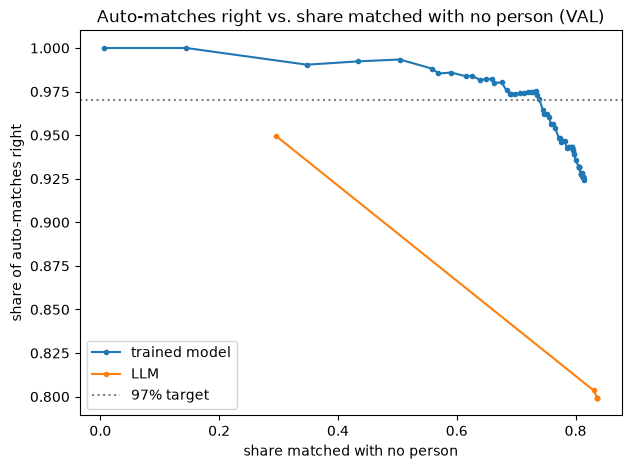

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, df in [("trained model", model_curve), ("LLM", llm_curve)]:
    ax.plot(df["auto_share"], df["auto_precision"], marker=".", label=name)
ax.axhline(0.97, color="gray", linestyle=":", label="97% target")
ax.set(title="Auto-matches right vs. share matched with no person (VAL)", xlabel="share matched with no person",
       ylabel="share of auto-matches right")
ax.legend()
plt.show()

### Does the LLM's confidence mean what it says?

The same bins as section 6, for the model's P(auto) and the LLM's confidence over 100, on the same entries.

In [23]:
key = answers.set_index("entry_id")
safe = lambda ids, picks: (picks.to_numpy() == ids.map(key["key_true_cmid"]).to_numpy()) & ids.map(key["key_secondary_cmid"]).isna().to_numpy()
calib = pd.concat({
    "model": pd.DataFrame({"score": model_top["p_auto"], "safe": safe(model_top["entry_id"], model_top["top_cmid"])}),
    "LLM": pd.DataFrame({"score": llm["confidence"] / 100, "safe": safe(llm["entry_id"], llm["cmid"])}),
}, names=["who"]).reset_index(level=0)
calib["band"] = pd.cut(calib["score"], bins, right=False)
calib.groupby(["who", "band"], observed=True)["safe"].agg(entries="size", share_safe="mean").round(3).unstack(0)

entries        share_safe       
who              LLM  model        LLM  model
band                                         
[0.0, 0.5)      34.0   83.0      0.647  0.169
[0.5, 0.8)      20.0   63.0      0.300  0.603
[0.8, 0.9)       8.0   52.0      0.125  0.885
[0.9, 0.95)    361.0   47.0      0.679  0.957
[0.95, 0.97)   178.0   20.0      0.949  0.950
[0.97, 0.99)     NaN   75.0        NaN  0.973
[0.99, 1.0)      NaN  261.0        NaN  0.992

### Sibling matters

The hardest silent errors are the right client but the wrong matter, often the one the timekeeper bills most. These are the entries where the right matter isn't the timekeeper's most-billed matter at that client, so the narrative has to outweigh the history. Each is scored on whether its first pick is the right matter.

In [24]:
client_of = ref["matters"].set_index("cmid")["client"]
hours = ref["history"].assign(hours=lambda d: pd.to_numeric(d["hours"], errors="coerce"), client=lambda d: d["cmid"].map(client_of))
favorite = hours.sort_values("hours", ascending=False).drop_duplicates(["tk_id", "client"]).set_index(["tk_id", "client"])["cmid"]
one = val_run["entries"][["entry_id", "tk_id"]].merge(answers[["entry_id", "key_true_cmid", "key_secondary_cmid"]], on="entry_id")
one = one[one["entry_id"].isin(ids) & (one["key_true_cmid"] != "NONE") & one["key_secondary_cmid"].isna()].copy()
one["favorite"] = [favorite.get((t, client_of.get(c))) for t, c in zip(one["tk_id"], one["key_true_cmid"])]
one["group"] = np.select([one["favorite"].isna(), one["favorite"] == one["key_true_cmid"]],
                         ["no history at the client", "right matter is the most-billed"], "right matter isn't the most-billed")
one["model_right"] = one["entry_id"].map(model_top.set_index("entry_id")["top_cmid"]) == one["key_true_cmid"]
one["llm_right"] = one["entry_id"].map(llm.set_index("entry_id")["cmid"]) == one["key_true_cmid"]
one.groupby("group").agg(entries=("entry_id", "size"), model_right=("model_right", "mean"), llm_right=("llm_right", "mean")).round(3)

,entries,model_right,llm_right
group,,,
no history at the client,69,0.899,0.696
right matter is the most-billed,403,0.968,0.829
right matter isn't the most-billed,55,0.764,0.600


**Takeaways**

- **The LLM's confidence can't be used as a cutoff.** It answered 90 or 95 on 90% of entries, and at 90 it was safe 68% of the time, against 96% for the model's 0.90 to 0.95 band. Published work finds the same: LLMs tend to be overconfident when they state their confidence (Xiong et al., "Can LLMs Express Their Uncertainty?", ICLR 2024).
- Its 95s are about right (safe 95% of the time) but cover only 30% of entries.
- **Sibling matters:** where the narrative has to outweigh the timekeeper's most-billed matter at the client, the LLM is right 60% of the time and the model 76%. With no history at the client, 70% against 90%.

### Time, cost, and the same answer twice

- **Time:** seconds per entry. The LLM's is per call; with several calls at once, a batch takes less.
- **Cost:** tokens per entry, priced with `PRICE_PER_M` when it's filled in. Cached input is the system prompt read from Bedrock's cache.
- **Same answer twice:** the entries `01_llm_answers` asked a second time, compared with their first answer.

In [25]:
usage = pd.DataFrame(list(llm["usage"])).fillna(0)
tokens = {"input": float(usage.get("inputTokens", pd.Series([0])).mean()),
          "output": float(usage.get("outputTokens", pd.Series([0])).mean()),
          "cache_read": float(usage.get("cacheReadInputTokens", pd.Series([0])).mean())}
priced = all(v is not None for v in PRICE_PER_M.values())
cost = sum(tokens[k] * PRICE_PER_M[k] for k in tokens) / 1e6 if priced else None

again = pd.DataFrame([json.loads(p.read_text()) for p in sorted((LLM_DIR / "repeat").glob("*.json"))])
first = llm.set_index("entry_id").reindex(again["entry_id"]) if len(again) else llm.head(0)
repeat = {"entries": len(again),
          "same_matter": float((again["cmid"].to_numpy() == first["cmid"].to_numpy()).mean()) if len(again) else None,
          "confidence_within_10": float((abs(again["confidence"].to_numpy() - first["confidence"].to_numpy()) <= 10).mean()) if len(again) else None}

print("Asked twice:", repeat)
pd.DataFrame({"trained model": {"seconds per entry": val_run["seconds"], "input tokens": 0, "output tokens": 0, "USD per 1,000 entries": 0},
              "LLM": {"seconds per entry": llm["seconds"].mean(), "input tokens": tokens["input"], "output tokens": tokens["output"],
                      "USD per 1,000 entries": cost * 1000 if priced else np.nan}}).T.round(3)

Asked twice: {'entries': 30, 'same_matter': 0.9333333333333333, 'confidence_within_10': 0.9333333333333333}


,seconds per entry,input tokens,output tokens,"USD per 1,000 entries"
trained model,0.004,0.000,0.000,0.000
LLM,4.402,201.767,86.421,2.355


In [26]:
def plain(value):
    return None if pd.isna(value) else float(value)


llm_report = {"model_dir": LLM_DIR.name, "entries": len(llm),
              "results": {name: {k: plain(row[k]) for k in LLM_COLS} for name, row in llm_runs.items()},
              "first_pick": {k: plain(v) for k, v in first_pick.items()}, "first_pick_p_value": p_value,
              "none_answers": none_answers,
              "seconds_per_entry": {"model": val_run["seconds"], "llm": float(llm["seconds"].mean())},
              "tokens_per_entry": tokens, "usd_per_1000_entries": cost * 1000 if priced else None, "repeat": repeat}
(RESULTS_DIR / "llm_comparison.json").write_text(json.dumps(llm_report, indent=2, default=float))
print("Saved llm_comparison.json")

Saved llm_comparison.json


**Takeaways**

- **About 1,000 times slower:** 4.4 seconds per entry against 0.004.
- **Cost:** about $2.35 per 1,000 entries at Nova Pro's prices. Each entry is about 200 input and 86 output tokens, plus about 9,600 cached tokens for the system prompt (the matter list and past entries), which is most of the cost. Without the cache it would be about $8 per 1,000.
- **The trained model** runs on the app's own server in about 4 seconds of compute per 1,000 entries, so it costs nothing per entry beyond that server, which either approach needs.
- **Asked twice at temperature 0,** it gave the same matter for 28 of 30 entries (93%). The model gives the same answer every time.

### Every LLM, side by side

Every model folder in `data/llm_answers/` scored the same way as above, on the same VAL entries each one answered:
- **First pick right:** on entries with one known matter, the LLM's first matter and the model's top pick, with the paired test from above.
- **Taken at its word:** the LLM's decisions at confidence 90 or more (its share decided alone, how often those are right, and its silent errors).
- **The model at the same share:** `auto_min` set so the model decides about the same share alone, so the two are compared on errors alone.
- **Time and cost:** seconds per entry, and USD per 1,000 entries for any folder priced in `PRICES`.

In [27]:
LLM_ROOT = Path("../data/llm_answers")
PRICES = {   # USD per million tokens by answer folder, from the Bedrock pricing page; add a line to price another model
    "us.amazon.nova-pro-v1_0": PRICE_PER_M,
    "openai.gpt-oss-120b-1_0": {"input": 0.15, "output": 0.60, "cache_read": 0.0},
}
TOKEN_COLS = {"input": "inputTokens", "output": "outputTokens", "cache_read": "cacheReadInputTokens"}
MODEL_SHARES = np.round(np.r_[np.arange(0.3, 0.99, 0.01), 0.99, 0.995, 0.998, 0.999], 3)


def load_llm(folder):
    found = val_run["entries"][["entry_id"]].merge(pd.DataFrame([json.loads(p.read_text()) for p in sorted(folder.glob("*.json"))]), on="entry_id")
    for col in ["cmid", "second_cmid", "reason"]:
        found[col] = found[col].fillna("").astype(str).str.strip()
    found["confidence"] = pd.to_numeric(found["confidence"], errors="coerce").fillna(0).clip(0, 100)
    found["shortlist"] = [s if isinstance(s, list) else [] for s in found["shortlist"]]
    return found


def compare_llm(folder):
    found = load_llm(folder)
    top = val_run["top"][val_run["top"]["entry_id"].isin(set(found["entry_id"]))].reset_index(drop=True)
    probs = top[["p_auto", "p_review", "p_multi", "p_no_match"]].rename(columns=lambda c: c[2:])
    at_90 = summarize(score(llm_decisions(found, 90), answers))
    shares = curve(lambda t: route_actions(top, probs, model_cutoffs(t)), MODEL_SHARES)
    same = (shares["auto_share"].astype(float) - float(at_90["auto_share"])).abs().idxmin()

    key = answers.set_index("entry_id").reindex(found["entry_id"])
    truth = key.loc[(key["key_true_cmid"] != "NONE") & key["key_secondary_cmid"].isna(), "key_true_cmid"]
    model_right = top.set_index("entry_id")["top_cmid"].reindex(truth.index) == truth
    llm_right = found.set_index("entry_id")["cmid"].reindex(truth.index) == truth
    only_model, only_llm = int((model_right & ~llm_right).sum()), int((llm_right & ~model_right).sum())

    repeat = [json.loads(p.read_text()) for p in sorted((folder / "repeat").glob("*.json"))]
    first = found.set_index("entry_id")["cmid"]
    same_twice = np.mean([str(r.get("cmid") or "").strip() == first.get(r["entry_id"], "") for r in repeat]) if repeat else np.nan

    usage = pd.DataFrame(list(found["usage"])).fillna(0)
    price = PRICES.get(folder.name)
    cost = sum(float(usage.get(col, pd.Series([0])).mean()) * price[k] for k, col in TOKEN_COLS.items()) / 1e6 * 1000 if price else np.nan
    return {"entries": len(found),
            "first pick right, LLM": llm_right.mean(),
            "first pick right, model": model_right.mean(),
            "p-value": float(binomtest(only_llm, only_model + only_llm, 0.5).pvalue) if only_model + only_llm else 1.0,
            "LLM at 90+: share alone": at_90["auto_share"],
            "LLM at 90+: right when alone": at_90["auto_precision"],
            "LLM at 90+: silent errors": at_90["silent_errors"],
            "model at the same share: silent errors": shares.loc[same, "silent_errors"],
            "same answer twice": same_twice,
            "seconds per entry": found["seconds"].mean(),
            "USD per 1,000 entries": cost}


llm_folders = [f for f in sorted(LLM_ROOT.iterdir()) if f.is_dir() and any(f.glob("*.json"))]
side_by_side = pd.DataFrame({f.name: compare_llm(f) for f in llm_folders}).T.astype(float)
(RESULTS_DIR / "llm_comparison_all.json").write_text(side_by_side.to_json(orient="index", indent=2))
print(f"Model at the default on the same VAL entries: {summarize(model_scored)['silent_errors']:.0f} silent errors (Nova Pro's entries)")
side_by_side.round(3)

Model at the default on the same VAL entries: 7 silent errors (Nova Pro's entries)


,entries,"first pick right, LLM","first pick right, model",p-value,LLM at 90+: share alone,LLM at 90+: right when alone,LLM at 90+: silent errors,model at the same share: silent errors,same answer twice,seconds per entry,"USD per 1,000 entries"
openai.gpt-oss-120b-1_0,601.0,0.833,0.937,0.0,0.769,0.848,70.0,24.0,0.833,4.401,1.557
us.amazon.nova-pro-v1_0,601.0,0.787,0.937,0.0,0.830,0.804,98.0,37.0,0.933,4.402,2.355


**Takeaways**

- **gpt-oss-120b is the stronger LLM, and it still loses to the model.** Its first pick is right 83.3% of the time, against Nova Pro's 78.7% and the model's 93.7% (p < 0.001 against the model for both).
- **Taken at its word (90 or more),** gpt-oss matches 77% of entries with no person, and 84.8% of those are right: 70 silent errors. The model at the same share has 24. For Nova Pro it's 98 against 37.
- **Same answer twice:** asked a second time, gpt-oss gave the same matter for 25 of 30 entries and Nova Pro for 28. The model gives the same answer every time.
- **Time and cost:** both take about 4.4 seconds per entry. gpt-oss costs about $1.56 per 1,000 entries (no prompt cache) and Nova Pro about $2.35.
- **Claude and OpenAI's GPT models weren't run:** school AWS accounts can't call them on Bedrock.

## 14. Findings

### Results
- **The system is safer and decides more than the rules on every set:** 97% to 98% of its decisions with no person are right, with 7 to 11 silent errors per set against the rules' 36 to 50.
- **"How sure" works as a cutoff:** P(auto) is calibrated within 5 points, and above 0.95 an auto-match is wrong about 1 time in 90 on VAL and TEST (8 of 700).
- **Review is mostly confirmation, but these clues can't tell those entries apart.** In the surest review band (P(auto) 0.80 to 0.90), 66 of 75 VAL and TEST entries had the right top pick and 9 didn't, so auto-matching that band would take silent errors from 18 to about 27. What helps instead is quick confirmation (the top pick preselected, bulk accept by P(auto)) and confirmed entries feeding billing history (`add_confirmed`), which helps new timekeepers most.
- **Multi-matter entries are the hardest area, and hours and narrative length help.** 84%, 73%, and 92% are caught, with multi-matter PR-AUC 0.84, 0.79, and 0.90. The cost is more false multi-matter alarms (17, 12, and 31) and about 1 point less automation. The synthetic multi-matter entries are long by design, so a real firm would likely see a smaller gain and more false alarms from long entries on one matter.
- **The multi-matter entries still missed** mostly name the second matter by a word that is in neither its matter name nor much of its billing history: on TRAIN, the second matter had a median of 8 past single-matter entries. Terms learned from each matter's past entries (the firm's own key terms, with no one writing a list) and street names from matter names without the number ("Bay Rd.") were tried on the saved pairs and left out, since silent errors moved within noise. The multi-matter cutoff is picked on TRAIN (0.15 here) and moves between builds, as cutoffs for rare labels do, so PR-AUC is the steadier number to quote.
- **Neither LLM is a better matcher here:** with most of the same information, their first picks are right 10 to 15 points less often (gpt-oss-120b 83%, Nova Pro 79%, the model 94%). At the same share decided alone they make about 3 times the silent errors (70 against 24, 98 against 37), their stated confidence can't serve as a cutoff, and they're about 1,000 times slower. This backs keeping LLMs out of matching.

### Limitations
- Everything is synthetic: entries, typos, and phrasings come from one generator, so real entries will likely be messier. The holdout file's new phrasings and lateral hire are the closest check on unfamiliar data.
- Past narratives come from TRAIN only, so holdout entries are compared with history a few months older, as a firm's would be.
- Every timekeeper in TRAIN has billing history, so the models never see a new hire while training.
- Multi-matter entries are about 6% of the data, more than real firms see, and each set has only about 37, so one entry moves the multi-matter numbers by about 3 points.
- The LLM comparison is two models (Nova Pro and gpt-oss-120b) and one prompt, on VAL only. School AWS accounts can't call Claude or OpenAI's GPT models on Bedrock, so the strongest LLMs weren't tried. Its matter list had no codenames or client aliases, and it saw the first 3 past entries per matter while the model compares each entry with all of them. A stronger model, or the most similar past entries in the prompt, would likely narrow the accuracy gap further (gpt-oss-120b already narrowed it by about 5 points). The findings on stated confidence and speed are less likely to change.
- The LLM's prompt asks how sure it is of the first matter, so its NONE answers came with low confidence and count as review here.

## Appendix: the app's sample files

The "Try a sample" files in `data/samples/` were built from VAL and TEST entries whose decisions are known: three attorneys' notes (B. Quinn, I. Novak, C. Dunn) and a billing export with several timekeepers. Most entries match with no person, and each hard case shows up once. `data/sample_answer_key.csv` lists every entry as it's written in its file, the right matter, and the decision the file was built to show (`expected_action`).

This runs matching on those entries as written, with the source format each file gets in the app. It checks matching only: reading each file (and the hours and duplicate checks) is checked by uploading it in the app.

In [28]:
SAMPLE_KEY = Path("../data/sample_answer_key.csv")
FORMAT_OF = {"notebook.jpg": "HANDWRITTEN", "sticky-note.jpg": "HANDWRITTEN", "napkin.jpg": "HANDWRITTEN", "typed-note.txt": "EMAIL", "forwarded-email.eml": "EMAIL",
             "pdf-report.pdf": "PDF", "word-log.docx": "TYPED", "csv-export.csv": "TYPED", "excel-sheet.xlsx": "TYPED",
             "voice-memo.m4a": "EMAIL"}   # the app reads a memo's transcript as an email

sample_key = pd.read_csv(SAMPLE_KEY, dtype=str)
samples = sample_key.assign(entry_id=sample_key["file"] + "#" + sample_key.groupby("file").cumcount().astype(str),
                            source_format=sample_key["file"].map(FORMAT_OF), work_date=pd.to_datetime(sample_key["work_date"]),
                            hours=pd.to_numeric(sample_key["hours"]))
cols = ["entry_id", "tk_id", "source_format", "work_date", "cmid", "client", "matter", "narrative", "hours"]
_, _, sample_decisions = decide(samples[cols], ref)
samples = samples.merge(sample_decisions[["entry_id", "action", "reason_short"]], on="entry_id")
samples["as_built"] = samples["action"] == samples["expected_action"]

by_file = samples.groupby("file", sort=False).agg(entries=("entry_id", "size"), as_built=("as_built", "sum"),
                                                  no_person=("action", lambda a: (a == "AUTO_MATCH").mean()))
print(f"{samples['as_built'].sum()} of {len(samples)} sample entries decided as built | "
      f"matched with no person: {(samples['action'] == 'AUTO_MATCH').mean():.0%}")
display(by_file.round(2))
samples.loc[~samples["as_built"], ["file", "source_id", "narrative", "expected_action", "action", "reason_short"]]

96 of 96 sample entries decided as built | matched with no person: 84%


,entries,as_built,no_person
file,,,
typed-note.txt,5,5,0.80
word-log.docx,6,6,0.83
forwarded-email.eml,7,7,0.86
pdf-report.pdf,6,6,1.00
csv-export.csv,6,6,1.00
excel-sheet.xlsx,54,54,0.83
notebook.jpg,4,4,1.00
sticky-note.jpg,1,1,0.00
napkin.jpg,3,3,0.67


,file,source_id,narrative,expected_action,action,reason_short
